## 1. Setup

In [1]:
import os
import sys
from google.colab import drive
drive.mount("/content/drive")

REPO = "Arabic-sarcasm"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q transformers arabert emoji tashaphyne nltk

Mounted at /content/drive
Cloning into '/content/Arabic-sarcasm'...
remote: Enumerating objects: 321, done.
remote: Total 321 (delta 0), reused 0 (delta 0), pack-reused 321 (from 1)
Receiving objects: 100% (321/321), 3.68 MiB | 17.52 MiB/s, done.
Resolving deltas: 100% (154/154), done.
/content/Arabic-sarcasm
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Results, predictions and checkpoints are written straight to Google Drive, so a disconnected session loses nothing.

In [2]:
import shutil
from pathlib import Path

ROOT = Path("/content/Arabic-sarcasm")
DRIVE = Path("/content/drive/MyDrive/sarcasm")

for name in ["results", "predictions", "models"]:
    local, remote = ROOT / name, DRIVE / name
    if not remote.exists():                       # first time: copy what the repo already has
        if local.exists():
            shutil.copytree(local, remote)
        else:
            remote.mkdir(parents=True)
    if local.exists() and not local.is_symlink():
        shutil.rmtree(local)
    if not local.exists():
        local.symlink_to(remote)

## 2. Data

In [3]:
import sys
sys.path.insert(0, "/content/Arabic-sarcasm")

import warnings

import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer
from transformers import logging as hf_logging

from src.data import get_data
from src.evaluate import RESULTS, log_result, metrics, plot_results, save_predictions, show
from src.fine_tune import DEVICE, PLMS, MultiTask, SingleTask, predict_proba, prepare_text, train_model
from src.train import best_threshold, count_params, set_seed

hf_logging.set_verbosity_error()      # hide the model loading report
hf_logging.disable_progress_bar()
warnings.filterwarnings("ignore", message="Detected call of")   # harmless: fp16 skips the first optimizer step

MODEL = "marbert"
PLM = PLMS[MODEL]
MAX_LEN = PLM["max_len"]
SEEDS = [42, 43, 44]
LAMS = [0.3, 0.5, 1.0]

train, val, test, report = get_data()
print(report)

{'start': 11293, 'key_exact/dup_train': 54, 'key_exact/dup_val': 0, 'key_exact/dup_test': 4, 'key_exact/train_in_test': 2, 'key_exact/test_in_train': 2, 'key/dup_train': 331, 'key/dup_val': 4, 'key/dup_test': 5, 'key/train_in_test': 2, 'key/test_in_train': 2, 'conflict_groups': 59, 'conflict_rows': 120, 'removed_in_test': 2, 'removed_in_val': 72, 'removed_conflicting': 96, 'removed_duplicates': 281, 'end': 10842}


Texts are prepared once for all runs. Check 5 tweets before and after, and how many tweets are cut by `max_len`.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(PLM["hf_name"])

x_train = prepare_text(MODEL, train["tweet"])
x_val = prepare_text(MODEL, val["tweet"])
x_test = prepare_text(MODEL, test["tweet"])

y_train = train["sarcasm"].to_numpy()
s_train = train["sentiment_id"].to_numpy()
y_val = val["sarcasm"].to_numpy()
y_test = test["sarcasm"].to_numpy()

for before, after in zip(train["tweet"].head(5), x_train[:5]):
    print(before)
    print(after)
    print()

lengths = np.array([len(tokenizer(t)["input_ids"]) for t in x_train])
print("tweets longer than max_len:", (lengths > MAX_LEN).mean())

"#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"
"#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"

"RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"
"RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"

تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول
تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول

"RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الدجال عمياني بتتبعونه 😔😔😔😔"
"RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الدجال عمياني بتتبعونه 😔😔😔😔"

"أوباما يلاحق محمد بن سلمان !!: https://t.co/xDtS3uKFal via @YouTube

## 3. What one run does

In [5]:
def make_model(task, lam):
    if task == "single":
        model = SingleTask(PLM["hf_name"])
    else:
        model = MultiTask(PLM["hf_name"], lam)
    return model.to(DEVICE)


def already_done(name, seed):
    if not RESULTS.exists() or RESULTS.stat().st_size == 0:
        return False
    table = pd.read_csv(RESULTS)
    same = (table["model"] == name) & (table["preprocessing"] == PLM["prep"]) & (table["seed"] == seed)
    return bool(same.any())

In [6]:
def run_one(task, lam, seed):
    name = f"{MODEL}_{task}_lam{lam}"
    if already_done(name, seed):
        print("already done:", name, "seed", seed)
        return

    # 1. train (the model is left at its best epoch)
    set_seed(seed)
    model = make_model(task, lam)
    train_time = train_model(model, tokenizer, x_train, y_train, s_train, x_val, y_val, MAX_LEN)

    # 2. validation: choose the threshold
    val_proba = predict_proba(model, tokenizer, x_val, MAX_LEN)
    threshold = best_threshold(y_val, val_proba)
    val_scores = metrics(y_val, val_proba, threshold)

    # 3. test: use the validation threshold
    test_proba = predict_proba(model, tokenizer, x_test, MAX_LEN)
    test_scores = metrics(y_test, test_proba, threshold)
    save_predictions(name, seed, test["id"], y_test, test_proba, threshold)

    # 4. log
    row = {"model": name, "preprocessing": PLM["prep"], "seed": seed, "lam": lam,
           "threshold": threshold, "train_time": train_time, "trained_params": count_params(model)}
    row.update({"val_" + k: v for k, v in val_scores.items()})
    row.update({"test_" + k: v for k, v in test_scores.items()})
    log_result(**row)
    show(name, val_scores, threshold, train_time)

    # 5. checkpoint, first seed only
    if seed == SEEDS[0]:
        torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                    "hf_name": PLM["hf_name"], "task": task, "lam": lam, "prep": PLM["prep"],
                    "max_len": MAX_LEN, "threshold": threshold},
                   ROOT / "models" / f"{name}_seed{seed}.pt")

    torch.cuda.empty_cache()

In [7]:
run_one("single", 0, SEEDS[0]) #42

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6781


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6695


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6602
marbert_single_lam0          f1=0.6781  pr_auc=0.6978  threshold=0.67  151s


In [8]:
run_one("single", 0, SEEDS[1]) #43

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6592


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6667


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6728


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6826
marbert_single_lam0          f1=0.6826  pr_auc=0.6700  threshold=0.40  197s


In [9]:
run_one("single", 0, SEEDS[2]) #44

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6721


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6792


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6708


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6439
marbert_single_lam0          f1=0.6792  pr_auc=0.6932  threshold=0.69  195s


In [10]:
run_one("multi", LAMS[0], SEEDS[0]) #42


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6628


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6682


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6588


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6533
marbert_multi_lam0.3         f1=0.6682  pr_auc=0.6767  threshold=0.61  196s


In [11]:
run_one("multi", LAMS[1], SEEDS[0]) #42

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6750


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6610


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6696
marbert_multi_lam0.5         f1=0.6750  pr_auc=0.6910  threshold=0.59  147s


In [12]:
run_one("multi", LAMS[2], SEEDS[0]) #42

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6583


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6573


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6652


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6693
marbert_multi_lam1.0         f1=0.6693  pr_auc=0.6746  threshold=0.31  196s


In [13]:
run_one("multi", LAMS[0], SEEDS[1]) #43

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6513


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6697


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6842


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6695
marbert_multi_lam0.3         f1=0.6842  pr_auc=0.6778  threshold=0.75  196s


In [14]:
run_one("multi", LAMS[1], SEEDS[1]) #43

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6521


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6558


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6738


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6813
marbert_multi_lam0.5         f1=0.6813  pr_auc=0.6664  threshold=0.52  196s


In [15]:
run_one("multi", LAMS[2], SEEDS[1]) #43

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6550


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6604


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6638


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6734
marbert_multi_lam1.0         f1=0.6734  pr_auc=0.6743  threshold=0.37  196s


In [16]:
run_one("multi", LAMS[0], SEEDS[2]) #44

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6711


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6841


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6855


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6667
marbert_multi_lam0.3         f1=0.6855  pr_auc=0.7001  threshold=0.68  195s


In [17]:
run_one("multi", LAMS[1], SEEDS[2]) #44

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6757


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6866


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6811


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6681
marbert_multi_lam0.5         f1=0.6866  pr_auc=0.7012  threshold=0.74  195s


In [18]:
run_one("multi", LAMS[2], SEEDS[2]) #44

epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6578


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6752


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6762


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6681
marbert_multi_lam1.0         f1=0.6762  pr_auc=0.6869  threshold=0.58  196s


## 5. Results
Validation F1 of the sarcastic class, mean and std over the 3 seeds (`count` must be 3 for every row).

In [19]:
results = pd.read_csv(RESULTS)
results = results[(results["preprocessing"] == PLM["prep"]) & results["model"].str.contains("_single_|_multi_")]

val_table = results.groupby("model")["val_f1"].agg(["mean", "std", "count"])
val_table

,mean,std,count
model,,,
marbert_multi_lam0.3,0.679276,0.009655,3
marbert_multi_lam0.5,0.680962,0.005792,3
marbert_multi_lam1.0,0.672950,0.003461,3
marbert_single_lam0,0.679962,0.002352,3


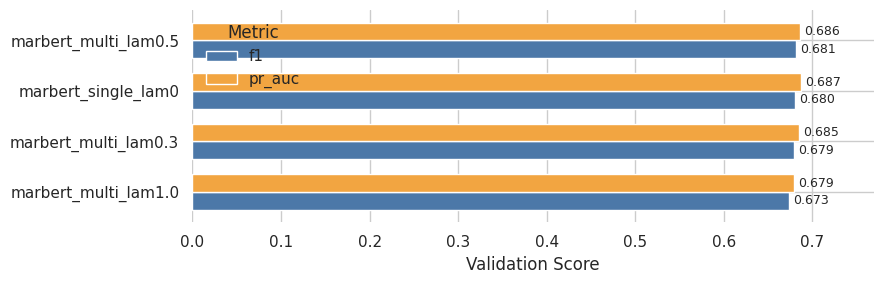

In [21]:
plot_table = results.groupby("model")[["val_f1", "val_pr_auc"]].mean()
plot_table.columns = ["f1", "pr_auc"]
plot_results(plot_table)

λ is chosen from the validation table. Test is shown only for E1 and the chosen E2.

In [20]:
multi = val_table[val_table.index.str.contains("_multi_")]
best_e2 = multi["mean"].idxmax()
print("chosen E2:", best_e2)

chosen = [f"{MODEL}_single_lam0", best_e2]
results[results["model"].isin(chosen)].groupby("model")["test_f1"].agg(["mean", "std"])

chosen E2: marbert_multi_lam0.5


,mean,std
model,,
marbert_multi_lam0.5,0.626287,0.008973
marbert_single_lam0,0.618699,0.004483
